In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [3]:
dataset, variances = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


In [420]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [421]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

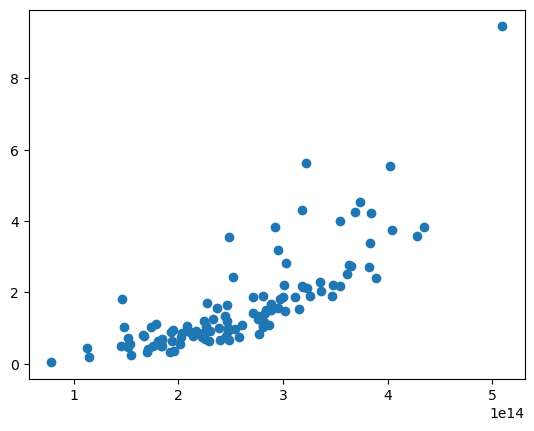

In [422]:
plt.scatter([nfw.M500 for nfw in nfws],[nfw.L500 for nfw in nfws])

In [423]:
test_nfw=nfws[0]

In [424]:
test_nfw.L_indep_factors

array([7.41841576e+78, 7.87357381e+78, 7.54462852e+78, 7.23062966e+78,
       6.93103248e+78, 6.64532408e+78, 6.37302224e+78, 6.11367428e+78,
       5.86685570e+78, 5.63216851e+78, 5.40923922e+78, 5.19771642e+78,
       4.99726757e+78, 4.80757503e+78, 4.62833108e+78, 4.45923146e+78,
       4.29996745e+78, 4.15021586e+78, 4.00962681e+78, 3.87780884e+78,
       3.75431117e+78, 3.63860299e+78, 3.53004982e+78, 3.42788754e+78,
       3.33119513e+78, 3.23886784e+78, 3.14959378e+78, 3.06183782e+78,
       2.97383818e+78, 2.88362238e+78, 2.78904994e+78, 2.68788945e+78,
       2.57793625e+78, 2.45717324e+78, 2.32397166e+78, 2.17731978e+78,
       2.01705624e+78, 1.84407430e+78, 1.66045388e+78, 1.46947703e+78,
       1.27549056e+78, 1.08360091e+78, 8.99219077e+77, 7.27510961e+77,
       5.72840812e+77, 4.38309806e+77, 3.25479711e+77, 2.34332839e+77,
       1.63464251e+77, 1.35119826e+77])

In [179]:
range(-40, -25)

range(-40, -25)

0.5853001790934521
0.5853001790935195
0.5853001790942017
0.585300179101024
0.5853001791692424
0.5853001798514258
0.5853001866732511
0.5853002548915124
0.5853009370741704
0.5853077589073562
0.5853759778974211
0.586058233624999
0.5928873801536845
0.6618443504262493
1.424594397311215


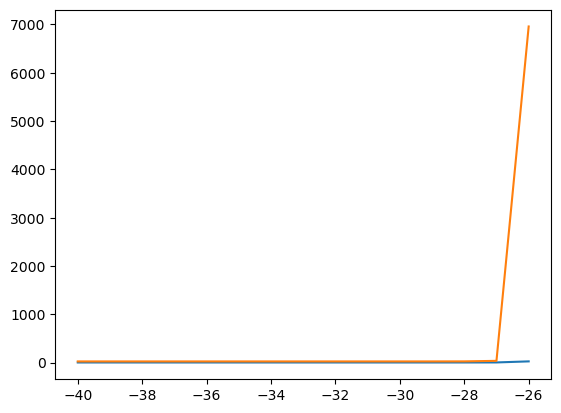

In [182]:
plt.plot([s for s in range(-40, -25)], [test_nfw.L500_numerical(1e-2, 10**s) for s in range(-40, -25)])

In [17]:
test_nfw.L500.value, test_nfw.L_err

(0.846881, 0.136706611275864)

In [470]:
p0=[-27, -2]
obs = [n.L500.value for n in nfws]

In [510]:
variances = np.array([n.L_err for n in nfws])

In [512]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

print(log_lik(p0, obs, nfws, variances))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

-35.73657735978669
         125466 function calls in 0.239 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.239    0.119 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    0.239    0.119 {built-in method builtins.exec}
        1    0.000    0.000    0.238    0.238 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:37(log_lik)
        1    0.001    0.001    0.231    0.231 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:68(<listcomp>)
      111    0.003    0.000    0.230    0.002 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:473(L500_numerical)
      333    0.001    0.000    0.225    0.001 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:672(brentq)
      333    0.002    0.000    

In [224]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)

Text(0, 0.5, 'net heating rate (erg/s)')

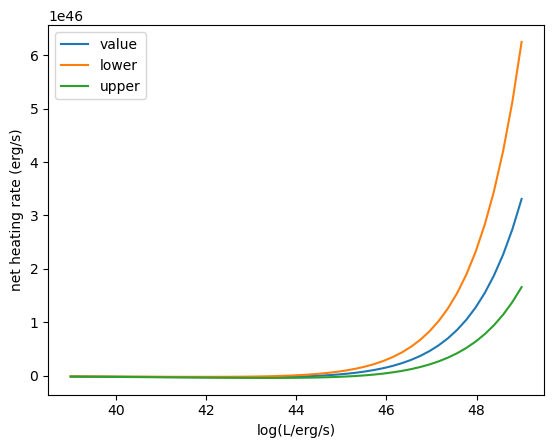

In [230]:
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')
#

Text(0, 0.5, 'net heating rate (erg/s)')

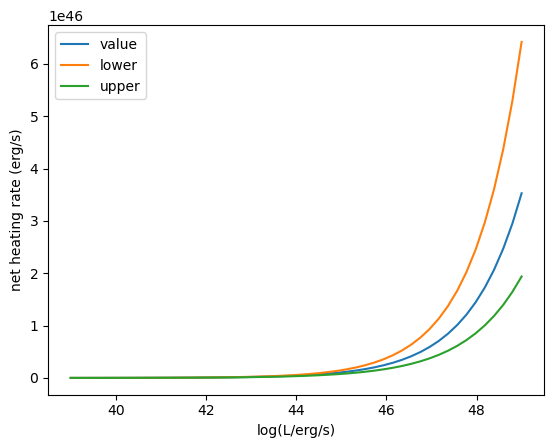

In [232]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

Text(0, 0.5, 'net heating rate (erg/s)')

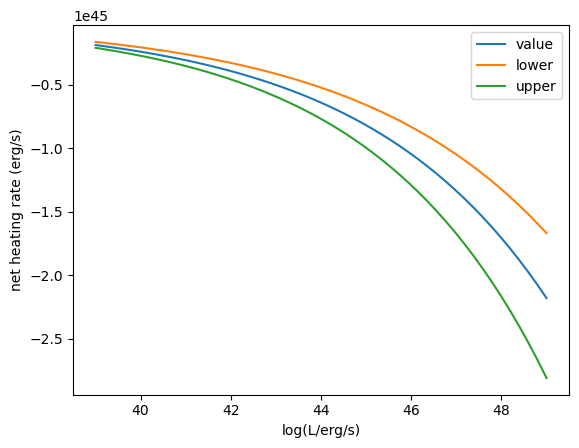

In [234]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

In [235]:
from cluster_error_prop import Linj_from_L500

Text(0, 0.5, 'logLinj (erg/s)')

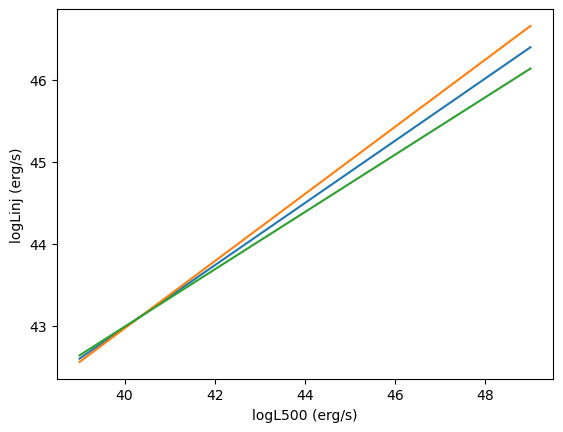

In [242]:
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5))))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='max')))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='min')))
plt.xlabel('logL500 (erg/s)')
plt.ylabel('logLinj (erg/s)')
#plt.yscale('log')

In [493]:
import numpy as np

# Create linearly spaced values from -40 to -30
s0_linear = np.linspace(-40, -29, 10)

# Create exponentially spaced values from -30 to -25
s0_exponential = -28 + np.geomspace(1, 5, 20) - 1

# Combine the arrays
s0_combined = np.concatenate((s0_linear, s0_exponential))

# Create the list of p0
p0_list = [[s0, -2] for s0 in s0_combined]

print(p0_list)

[[-40.0, -2], [-38.77777777777778, -2], [-37.55555555555556, -2], [-36.333333333333336, -2], [-35.111111111111114, -2], [-33.888888888888886, -2], [-32.666666666666664, -2], [-31.444444444444443, -2], [-30.22222222222222, -2], [-29.0, -2], [-28.0, -2], [-27.911601599269613, -2], [-27.815388921287536, -2], [-27.710671196441854, -2], [-27.59669659219169, -2], [-27.472646815201934, -2], [-27.33763123631532, -2], [-27.190680496181443, -2], [-27.030739545633587, -2], [-26.856660070846, -2], [-26.667192248887204, -2], [-26.460975774477383, -2], [-26.236530093525474, -2], [-25.99224377332657, -2], [-25.726362933101775, -2], [-25.436978651816258, -2], [-25.122013262868588, -2], [-24.779205437252518, -2], [-24.406093948094124, -2], [-24.0, -2]]


In [494]:
log_liks = [log_lik(p, obs, nfws) for p in p0_list]
log_liks

outside prior
outside prior
outside prior


[-33.50657649132892,
 -33.50657649133242,
 -33.506576491390724,
 -33.506576492363166,
 -33.50657650858402,
 -33.50657677916452,
 -33.506581292719396,
 -33.5066565833745,
 -33.507912513302216,
 -33.5288643687363,
 -33.729600522787955,
 -33.77998503604622,
 -33.84785008774729,
 -33.941003692919864,
 -34.071522672186475,
 -34.25851558182211,
 -34.53293890961136,
 -34.946132423297875,
 -35.58501034172676,
 -36.59831742317872,
 -38.23637863642814,
 -40.88171452898989,
 -44.92861981229032,
 -50.08734908622071,
 -54.22351143844337,
 -55.44436483795531,
 -55.4998894607886,
 -inf,
 -inf,
 -inf]

Text(0.5, 1.0, 'log likelihood without variance on scaling relations')

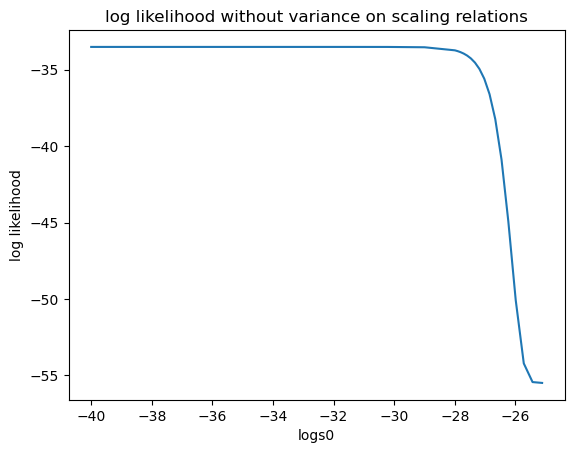

In [495]:
plt.plot(s0_combined, log_liks)
plt.xlabel('logs0')
plt.ylabel('log likelihood')


plt.title('log likelihood without variance on scaling relations')

outside prior
outside prior
outside prior


Text(0.5, 1.0, 'log likelihood with variance on scaling relations')

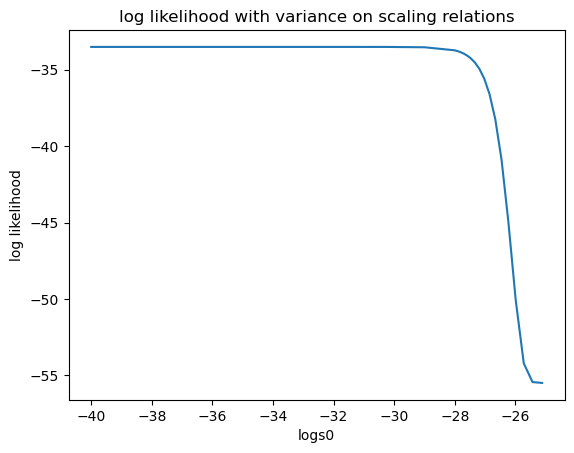

In [501]:
log_liks2 = [log_lik(p, obs, nfws) for p in p0_list]
log_liks2
plt.plot(s0_combined, log_liks2)
plt.xlabel('logs0')
plt.ylabel('log likelihood')


plt.title('log likelihood with variance on scaling relations')

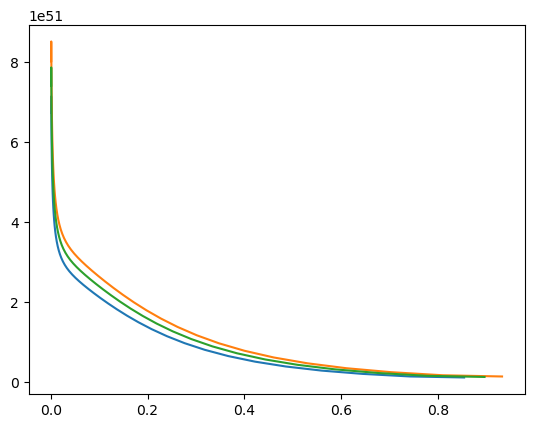

In [382]:
plt.plot(test_nfw.precalc.rs_min,test_nfw.precalc.L_indep_factors_min*1e-27)
plt.plot(test_nfw.precalc.rs_max,test_nfw.precalc.L_indep_factors_max*1e-27)
plt.plot(test_nfw.rs_Mpc, test_nfw.L_indep_factors*1e-27)

In [387]:
print( np.trapz( test_nfw.L_indep_factors*1e-30*(np.sqrt(test_nfw.Tbs)), test_nfw.rs_Mpc))

2.03483500618578e+45 (+2.747082367460992e+44, -2.7581599246054692e+44)


In [391]:
print( np.trapz( test_nfw.precalc.L_indep_factors_min*1e-30*(np.sqrt(test_nfw.Tbs)), test_nfw.precalc.rs_min))

1.7559218135589994e+45 (+8.710819695594774e+43, -8.704438050265718e+43)


In [390]:
print( np.trapz( test_nfw.precalc.L_indep_factors_max*1e-30*(np.sqrt(test_nfw.Tbs)),test_nfw.precalc.rs_max))

2.2965440259260847e+45 (+1.1369143513096356e+44, -1.1360755040445824e+44)


In [466]:
s0_values = np.logspace(-30,-24, 20)
s0_values

array([1.00000000e-30, 2.06913808e-30, 4.28133240e-30, 8.85866790e-30,
       1.83298071e-29, 3.79269019e-29, 7.84759970e-29, 1.62377674e-28,
       3.35981829e-28, 6.95192796e-28, 1.43844989e-27, 2.97635144e-27,
       6.15848211e-27, 1.27427499e-26, 2.63665090e-26, 5.45559478e-26,
       1.12883789e-25, 2.33572147e-25, 4.83293024e-25, 1.00000000e-24])

In [467]:
test_nfw.L_indep_factors

array([7.41841576e+78, 7.87357381e+78, 7.54462852e+78, 7.23062966e+78,
       6.93103248e+78, 6.64532408e+78, 6.37302224e+78, 6.11367428e+78,
       5.86685570e+78, 5.63216851e+78, 5.40923922e+78, 5.19771642e+78,
       4.99726757e+78, 4.80757503e+78, 4.62833108e+78, 4.45923146e+78,
       4.29996745e+78, 4.15021586e+78, 4.00962681e+78, 3.87780884e+78,
       3.75431117e+78, 3.63860299e+78, 3.53004982e+78, 3.42788754e+78,
       3.33119513e+78, 3.23886784e+78, 3.14959378e+78, 3.06183782e+78,
       2.97383818e+78, 2.88362238e+78, 2.78904994e+78, 2.68788945e+78,
       2.57793625e+78, 2.45717324e+78, 2.32397166e+78, 2.17731978e+78,
       2.01705624e+78, 1.84407430e+78, 1.66045388e+78, 1.46947703e+78,
       1.27549056e+78, 1.08360091e+78, 8.99219077e+77, 7.27510961e+77,
       5.72840812e+77, 4.38309806e+77, 3.25479711e+77, 2.34332839e+77,
       1.63464251e+77, 1.35119826e+77])

In [468]:
L_sols = [test_nfw.L500_numerical(1e-2, s) for s in s0_values]

3.8492487542886824 2.2289399372402228
3.8499671059447844 2.2294525149977926
3.8514539479693988 2.2305135162988496
3.854532456724301 2.2327106187627024
3.8609110059821345 2.2372642051442337
3.874146396911796 2.246718310670555
3.9016926972899957 2.2664184268199468
3.9593837975755313 2.3077798806668546
4.081789653108215 2.3959932174103367
4.348644892700459 2.590388206682099
4.964579016194479 3.049333228084924
6.57115621304119 4.305535262783454
12.074295954076605 9.090979346811304
48.57115831751033 49.87734320355745
1611.9350962663902 3302.9080614294044
6308512.375971449 27946639.532343086
576688432134.8778 2917760966149.7734
7.65980326987409e+16 3.903938988951845e+17
1.0378088060946519e+22 5.291407094245322e+22
1.4076120368362005e+27 7.177064893733065e+27


Text(0, 0.5, 'L (1e44 erg/s)')

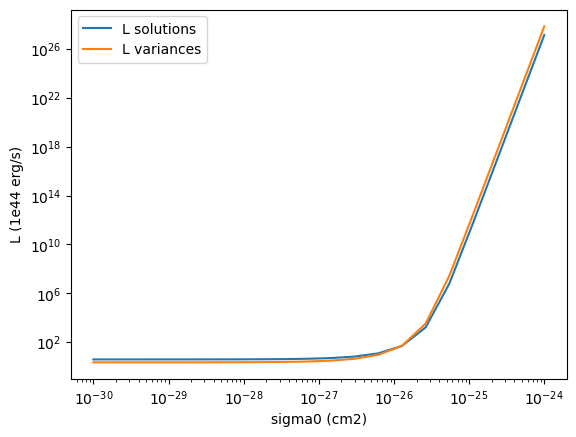

In [469]:
plt.plot(s0_values, [l.value for l in L_sols], label='L solutions')
plt.plot(s0_values, [l.plus for l in L_sols], label='L variances')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('sigma0 (cm2)')
plt.ylabel('L (1e44 erg/s)')

In [363]:
test_nfw.precalc.rad_factors_min

9.139833002873618e+40